# MoodMaps 问卷校准分析

## tl;dr

- 两份 Excel 是同一批 **209 份回答**的数字编码版与文本编码版；209 个序号全部一一对应，不能合并成 418 份。
- 在“最在意的因素”中，**拥堵 73.2%**、**天气差 60.3%**，明显高于红绿灯多 34.0%、转弯多 13.9% 和距离长 8.6%。
- **72.2%** 的人表示恶劣天气会让心情明显或稍微变差；外卖骑手的天气影响评分尤其高（均值 4.45/5）。天气值得进入模型，但应做成有上限、可缺失、可缓存的风险项。
- “距离长”不适合继续作为强惩罚：只有 8.6% 把它列入最在意因素，而且对长距离订单的态度分裂为 46.9% 更好、41.1% 更差、12.0% 无所谓。
- 建议 V2 权重为：**交通强度 32%、额外延误 20%、路线复杂度 20%、持续时长 12%、天气风险 16%**。天气不可用时，对其余四项自动重归一化，不阻塞评分。


## Context & Methods

这份分析用于给 Mood Score 提供“经验先验”，不是训练一个因果模型。问卷来自 2026 年 7 月 1–2 日的样本服务，身份为受访者自报；因此结论适合决定因素方向、相对重要性与权重上限，不足以证明某个因素会在真实驾驶中精确造成多少分变化。

### Key Assumptions

- 一行代表一位受访者。
- 数字版用于计算 1–5 级量表，文本版用于解释选项和多选题。
- 影响均值按 1=完全不影响、5=非常影响；“高影响”指 4 或 5。
- “问卷证据指数”仅用于排序：量表均值归一化后与前三选择率各占一半。产品权重还会对外部有效性和可观测性做保守收缩。


In [1]:
from pathlib import Path
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

plt.rcParams.update({
    "font.sans-serif": ["PingFang SC", "Arial Unicode MS", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "figure.dpi": 120,
})

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
RAW_PATH = ROOT / "analysis" / "raw" / "survey-workbooks.json"
raw = json.loads(RAW_PATH.read_text(encoding="utf-8"))

def to_frame(encoding):
    sheet = next(item for item in raw if item["encoding"] == encoding)["sheets"][0]
    headers, *rows = sheet["values"]
    return pd.DataFrame(rows, columns=headers)

numeric = to_frame("numeric")
text = to_frame("text")
numeric["序号"] = numeric["序号"].astype(str)
text["序号"] = text["序号"].astype(str)

numeric.shape, text.shape


((209, 25), (209, 18))

## Data

### 1. 核对两份导出是否真的是同一批回答


In [2]:
quality = {
    "numeric_rows": len(numeric),
    "text_rows": len(text),
    "numeric_unique_ids": numeric["序号"].nunique(),
    "text_unique_ids": text["序号"].nunique(),
    "paired_ids": len(set(numeric["序号"]) & set(text["序号"])),
    "numeric_only_ids": len(set(numeric["序号"]) - set(text["序号"])),
    "text_only_ids": len(set(text["序号"]) - set(numeric["序号"])),
    "closed_question_missing_cells": int(
        text.filter(regex=r"^[1-7]、").isin([None, "", "(空)"]).sum().sum()
    ),
}
pd.Series(quality, name="value").to_frame()


,value
numeric_rows,209
text_rows,209
numeric_unique_ids,209
text_unique_ids,209
paired_ids,209
numeric_only_ids,0
text_only_ids,0
closed_question_missing_cells,0


In [3]:
response_seconds = text["所用时间"].str.extract(r"(\d+)")[0].astype(int)
source_summary = pd.DataFrame({
    "指标": ["最短答题时间", "中位答题时间", "90秒内完成", "来源为样本服务", "Q3完全直线作答"],
    "结果": [
        f"{response_seconds.min()} 秒",
        f"{response_seconds.median():.0f} 秒",
        f"{(response_seconds < 90).mean():.1%}",
        f"{(text['来源'] == '样本服务').mean():.1%}",
        "稍后计算",
    ],
})
source_summary


,指标,结果
0,最短答题时间,61 秒
1,中位答题时间,75 秒
2,90秒内完成,60.3%
3,来源为样本服务,100.0%
4,Q3完全直线作答,稍后计算


质量判断：封闭题没有缺失，且两份导出可通过回答序号完全配对，这是积极信号；但全部来自同一个样本服务，而且 60.3% 在 90 秒内完成，样本代表性和快速作答风险都需要作为权重收缩理由。逐行数据只作为本地、被忽略的中间文件使用；仓库发布的只有聚合证据，不包含 IP、精确提交时间、来源详情或自由文本。

## Results

### 2. 拥堵和天气是最稳定的可观测信号


In [4]:
factors = [
    ("天气", "3、以下因素对你“是否愿意接单/驾驶”的影响有多大？—天气不好，例如下雨、大雾、暴雨", "天气差"),
    ("周末/节假日", "3、周末/节假日", "周末/节假日"),
    ("拥堵", "3、路线拥堵", "拥堵严重"),
    ("红绿灯", "3、红绿灯太多", "红绿灯多"),
    ("转弯/复杂", "3、转弯太多、路线复杂", "转弯多"),
    ("目的地偏远", "3、目的地偏远", "目的地偏远"),
    ("乘客态度", "3、乘客/顾客评分或态度较差", "乘客/顾客评分或态度较差"),
    ("距离长", "3、路线距离较长", "距离长"),
]

top_three_col = "6、如果一个订单/驾驶有以下情况，你最在意哪三个？"
top_three_sets = text[top_three_col].fillna("").map(
    lambda value: {item.strip() for item in value.split("┋") if item.strip() and item.strip() != "(空)"}
)

rng = np.random.default_rng(20260717)
factor_rows = []
for label, column, selection_label in factors:
    values = numeric[column].astype(float).to_numpy()
    bootstrap_means = np.mean(rng.choice(values, size=(5000, len(values)), replace=True), axis=1)
    mean = values.mean()
    high_share = np.mean(values >= 4)
    top_three_share = np.mean(top_three_sets.map(lambda selected: selection_label in selected))
    normalized_mean = (mean - 1) / 4
    factor_rows.append({
        "因素": label,
        "平均影响(1-5)": mean,
        "均值95%CI下限": np.quantile(bootstrap_means, 0.025),
        "均值95%CI上限": np.quantile(bootstrap_means, 0.975),
        "高影响占比": high_share,
        "进入前三占比": top_three_share,
        "问卷证据指数": (normalized_mean + top_three_share) / 2,
    })

factor_summary = pd.DataFrame(factor_rows).sort_values("问卷证据指数", ascending=False).reset_index(drop=True)
factor_summary.index += 1
factor_summary.round(3)


,因素,平均影响(1-5),均值95%CI下限,均值95%CI上限,高影响占比,进入前三占比,问卷证据指数
1,拥堵,3.957,3.828,4.077,0.727,0.732,0.736
2,天气,4.263,4.134,4.388,0.842,0.603,0.709
3,乘客态度,3.971,3.852,4.096,0.722,0.378,0.560
4,目的地偏远,3.847,3.694,3.995,0.699,0.373,0.542
5,红绿灯,3.756,3.617,3.885,0.679,0.340,0.514
6,转弯/复杂,3.761,3.617,3.895,0.684,0.139,0.414
7,周末/节假日,3.124,2.967,3.282,0.411,0.211,0.371
8,距离长,3.507,3.368,3.641,0.569,0.086,0.356


量表均值与前三选择率的 Spearman 相关：rho=0.810, p=0.015


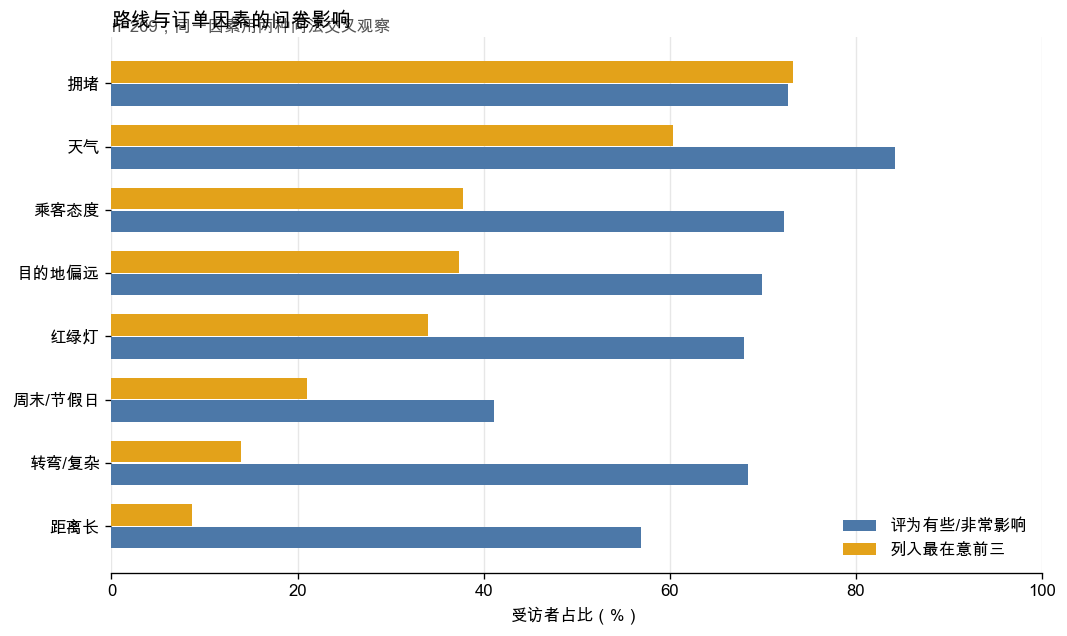

In [5]:
rank_corr = spearmanr(
    factor_summary["平均影响(1-5)"],
    factor_summary["进入前三占比"],
)
print(f"量表均值与前三选择率的 Spearman 相关：rho={rank_corr.statistic:.3f}, p={rank_corr.pvalue:.3f}")

plot_data = factor_summary.sort_values("进入前三占比")
y = np.arange(len(plot_data))
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.barh(y - 0.18, plot_data["高影响占比"] * 100, height=0.34, color="#4C78A8", label="评为有些/非常影响")
ax.barh(y + 0.18, plot_data["进入前三占比"] * 100, height=0.34, color="#E3A21A", label="列入最在意前三")
ax.set_yticks(y, plot_data["因素"])
ax.set_xlim(0, 100)
ax.set_xlabel("受访者占比（%）")
ax.set_title("路线与订单因素的问卷影响", loc="left", weight="bold")
ax.text(0, 1.01, "n=209；同一因素用两种问法交叉观察", transform=ax.transAxes, color="#555555")
ax.grid(axis="x", color="#E7E7E7", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()


图中两个问法并不完全一致：量表问“影响多大”，前三题问“最在意什么”。拥堵在两种问法上都强；天气在量表上最强、在前三中第二。红绿灯和转弯虽常被评为“有影响”，但抢占前三的能力弱，适合合并成一个中等权重的路线复杂度项。

### 3. 天气影响真实存在，但不同驾驶群体强度不同


In [6]:
joined = numeric[["序号", factors[0][1]]].merge(
    text[["序号", "1、你的身份是？", "4、如果遇到下雨、大雾或暴雨天气，你的接单/驾驶心情通常会怎样？"]],
    on="序号",
)
joined["weather_impact"] = joined[factors[0][1]].astype(float)
joined["mood_worsened"] = joined["4、如果遇到下雨、大雾或暴雨天气，你的接单/驾驶心情通常会怎样？"].isin(["明显变差", "有一点变差"])

weather_by_role = joined.groupby("1、你的身份是？").agg(
    样本量=("序号", "size"),
    天气影响均值=("weather_impact", "mean"),
    高影响占比=("weather_impact", lambda values: np.mean(values >= 4)),
    心情变差占比=("mood_worsened", "mean"),
).sort_values("天气影响均值", ascending=False)
weather_by_role.round(3)


,样本量,天气影响均值,高影响占比,心情变差占比
1、你的身份是？,,,,
其他驾驶/配送相关工作者,45,4.556,0.911,0.756
外卖骑手,84,4.452,0.881,0.762
网约车司机,59,3.949,0.780,0.695
出租车司机,21,3.762,0.714,0.571


In [7]:
weather_mood = text["4、如果遇到下雨、大雾或暴雨天气，你的接单/驾驶心情通常会怎样？"].value_counts().rename_axis("回答").to_frame("人数")
weather_mood["占比"] = weather_mood["人数"] / len(text)
weather_mood


,人数,占比
回答,,
有一点变差,93,0.444976
明显变差,58,0.277512
基本不变,31,0.148325
反而更愿意接，如果收入更高,27,0.129187


天气不应该被当成所有人的固定负分。骑手暴露程度更高，天气敏感度也更高；出租车司机相对较低。V2 先用统一且有上限的天气风险项，后续如果加入“工作类型/暴露模式”，再把天气权重做成用户侧微调。

### 4. 绝对距离不是稳定的负面因素


In [8]:
distance_attitude = text["7、对你来说，“长距离订单”通常是？"].value_counts().rename_axis("态度").to_frame("人数")
distance_attitude["占比"] = distance_attitude["人数"] / len(text)
distance_attitude


,人数,占比
态度,,
更好，因为收入可能更高,98,0.468900
更差，因为耗时和精力成本高,86,0.411483
基本无所谓,25,0.119617


长距离可能意味着更高收入，也可能意味着更高疲劳，方向取决于收入、返程和个人偏好。受支持地图的路线卡只能看到距离和时间，看不到收入与返程成本，所以模型应保留小幅“持续时长/疲劳”项，而不是直接对里程做强惩罚。

### 5. 数据质量限制决定了要保守调权


In [9]:
q3_columns = [column for _, column, _ in factors]
q3 = numeric[q3_columns].astype(int)
straight_lined = q3.nunique(axis=1).eq(1)
low_variation = q3.nunique(axis=1).le(2)
selection_sizes = top_three_sets.map(len)

quality_detail = pd.DataFrame({
    "检查": ["Q3八项完全相同", "Q3只用了两种或更少分值", "前三题恰好选择3项", "前三题少于3项"],
    "人数": [straight_lined.sum(), low_variation.sum(), selection_sizes.eq(3).sum(), selection_sizes.lt(3).sum()],
})
quality_detail["占比"] = quality_detail["人数"] / len(text)
quality_detail


,检查,人数,占比
0,Q3八项完全相同,2,0.009569
1,Q3只用了两种或更少分值,33,0.157895
2,前三题恰好选择3项,187,0.894737
3,前三题少于3项,22,0.105263


只有 2 人在八个影响题上完全直线作答，说明不是大面积机械同选；但 33 人只使用了两种或更少分值，且 22 人没有按题目要求选满三个因素。结合统一的样本服务来源，这份数据适合做有收缩的产品先验，不适合把问卷排名直接等比例转换成满权重。

## Takeaways

### 6. 建议的 V2 评分结构


In [10]:
model_weights = pd.DataFrame([
    {"模型项": "交通强度", "权重": 0.32, "主要数据": "可靠路段明细优先；否则用可见拥堵、ETA 或相对速度代理", "理由": "拥堵问卷证据最强"},
    {"模型项": "额外延误", "权重": 0.20, "主要数据": "可见 ETA、无交通时间和路线相对差异", "理由": "反映不可预期时间损失"},
    {"模型项": "路线复杂度", "权重": 0.20, "主要数据": "可靠 maneuver 优先；否则用路线名称结构代理", "理由": "合并红绿灯/转弯信号，避免重复计分"},
    {"模型项": "持续时长", "权重": 0.12, "主要数据": "路线时长", "理由": "保留疲劳项但降低绝对距离惩罚"},
    {"模型项": "天气风险", "权重": 0.16, "主要数据": "降水、能见度、阵风、天气类型", "理由": "强问卷信号，但对样本偏差与群体差异做收缩"},
])
model_weights["仅天气缺失时有效权重"] = np.where(
    model_weights["模型项"].eq("天气风险"),
    0,
    model_weights["权重"] / model_weights.loc[~model_weights["模型项"].eq("天气风险"), "权重"].sum(),
)
model_weights


,模型项,权重,主要数据,理由,仅天气缺失时有效权重
0,交通强度,0.32,可靠路段明细优先；否则用可见拥堵、ETA 或相对速度代理,拥堵问卷证据最强,0.380952
1,额外延误,0.20,可见 ETA、无交通时间和路线相对差异,反映不可预期时间损失,0.238095
2,路线复杂度,0.20,可靠 maneuver 优先；否则用路线名称结构代理,合并红绿灯/转弯信号，避免重复计分,0.238095
3,持续时长,0.12,路线时长,保留疲劳项但降低绝对距离惩罚,0.142857
4,天气风险,0.16,降水、能见度、阵风、天气类型,强问卷信号，但对样本偏差与群体差异做收缩,0.000000


In [11]:
factor_summary.to_csv(ROOT / "analysis" / "survey-factor-summary.csv", index=False, encoding="utf-8-sig")
model_weights.to_csv(ROOT / "analysis" / "proposed-model-weights.csv", index=False, encoding="utf-8-sig")

evidence = {
    "sample_size": len(text),
    "field_period": [text["提交答卷日期"].min(), text["提交答卷日期"].max()],
    "source": text["来源"].value_counts().to_dict(),
    "weather_mood_worsened_share": float(joined["mood_worsened"].mean()),
    "top_three_share": {
        row["因素"]: float(row["进入前三占比"])
        for _, row in factor_summary.iterrows()
    },
    "proposed_weights": {
        row["模型项"]: float(row["权重"])
        for _, row in model_weights.iterrows()
    },
    "quality": {
        **quality,
        "response_seconds_median": float(response_seconds.median()),
        "response_under_90_share": float((response_seconds < 90).mean()),
        "q3_straight_lined": int(straight_lined.sum()),
        "top_three_fewer_than_three": int(selection_sizes.lt(3).sum()),
    },
}
(ROOT / "analysis" / "survey-model-evidence.json").write_text(
    json.dumps(evidence, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Saved survey-factor-summary.csv, proposed-model-weights.csv, and survey-model-evidence.json")


Saved survey-factor-summary.csv, proposed-model-weights.csv, and survey-model-evidence.json


### 决策建议

1. 把天气作为 **16 分上限**的可选风险项放在扩展本地评分流程；查询失败或位置不够粗粒度时立即回退，不让 UI 长时间等待。
2. 把当前“持续时长”惩罚降到 12%，不新增独立里程惩罚。
3. 红绿灯、转弯、并线和掉头尽量汇总到一个路线复杂度项，防止同一段复杂道路被重复扣分。
4. 暂时不把周末/节假日、目的地偏远、乘客态度直接计分：前者方向受收入影响，后两者在受支持地图的可见路线卡中没有低成本、可靠且隐私友好的直接字段。
5. 下一轮应收集用户对实际路线的“预测分 vs. 真实感受”反馈，再用真实路线级数据校准权重；那会比继续扩大问卷更有价值。
